# Midterm EDA: general market analysis

The numbers and figures behind slides 4–6 of the midterm presentation: which data we have and when each dataset starts (slide 4), what was listed and traded between June 1 and October 5, 2026 (slide 5), and how quickly markets are created, resolved and closed (slide 6).

**Data.** `pull_data.py` caches the course data in `~/polymarket_cache` (catalog tables + 526 daily trade files). `export_raw_csv.py` later extended the trade files to Oct 27 in `raw_csv/`; only its coverage record is read here. Nothing here needs the database password.

**Plan.** 0 · The datasets and their date ranges. 1 · June 1 – October 5: markets, volume, resolved share and categories. 2 · Markets created and resolved per month, and actual vs. scheduled length.

In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import duckdb
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from IPython.display import display
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60); pd.set_option("display.max_columns", None)

DATA = Path("data")                                                            # tables from build_tables.py
CACHE = Path(os.environ.get("PM_CACHE", Path.home() / "polymarket_cache"))     # raw data from pull_data.py
RAW = Path("raw_csv")                                                          # extended export from export_raw_csv.py

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]                          # categorical slots, fixed order
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

db = duckdb.connect(); db.sql("SET TimeZone = 'UTC'")

# Category from the event slug (e) and title (t): the same rules as build_tables.py, first match wins.
db.sql(r"""
CREATE MACRO category(e, t) AS CASE
  WHEN regexp_matches(lower(e), '(^|-)(bitcoin|btc|ethereum|eth|solana|sol|xrp|doge|dogecoin|bnb|hype|zec|crypto)(-|$)')
    OR regexp_matches(lower(t), 'bitcoin|ethereum|solana|xrp|dogecoin|crypto|up or down') THEN 'crypto'
  WHEN regexp_matches(lower(e), '^(highest|lowest)-temperature|precipitation|hurricane|weather') THEN 'weather'
  WHEN regexp_matches(lower(e), '\d{4}-\d{2}-\d{2}') OR regexp_matches(lower(t), ' vs\.? | o/u |spread:|moneyline')
    OR regexp_matches(lower(t), 'world cup|fifa|nba|nfl|mlb|nhl|super bowl|champions league|premier league|la liga|serie a|bundesliga|stanley cup|grand prix|formula 1|ufc|mvp|heisman|ballon d|wimbledon|us open|french open|australian open|world series|playoffs|f1 |drivers. champion|constructors. champion') THEN 'sports'
  WHEN regexp_matches(lower(t), 'election|president|senate|governor|congress|parliament|prime minister|trump|democrat|republican|minister|mayor|ceasefire|war |iran|israel|ukraine|russia|china|tariff|supreme court|nominee|primary|hormuz|nato|venezuela|maduro|gaza|putin|zelensky|military|strike on|invade|pope|government shutdown|xi jinping|signed into law') THEN 'politics'
  WHEN regexp_matches(lower(t), 'fed |fed\b|interest rate|inflation|cpi|gdp|recession|unemployment|jobs report|s&p|nasdaq|stock|price of|ipo|market cap|earnings|oil') THEN 'economy'
  WHEN regexp_matches(lower(t), 'openai|gpt|gemini|anthropic|claude|google|apple|tesla|nvidia|spacex|microsoft|meta |ai model|ai |elon|musk|tweet') THEN 'tech'
  WHEN regexp_matches(lower(t), 'oscar|grammy|emmy|movie|film|box office|album|song|spotify|billboard|netflix|taylor swift|celebrity|tv |youtube|award') THEN 'entertainment'
  ELSE 'other'
END""")
GROUPS = {"politics": "Politics", "sports": "Sports", "crypto": "Crypto", "economy": "Economics"}   # the slides' five groups
GROUP_ORDER = ["Politics", "Sports", "Crypto", "Economics", "Other"]

res = pd.read_parquet(CACHE / "resolutions.parquet")
markets = (db.sql(f"""SELECT slug, event_slug, start_date, end_date, synced_at, category(event_slug, title) AS category
                      FROM '{CACHE}/markets.parquet'""").df()
           .merge(res[["market_slug", "resolved_at"]].rename(columns={"market_slug": "slug"}), on="slug", how="left"))
markets["group"] = markets.category.map(GROUPS).fillna("Other")
print(f"{len(markets):,} catalog markets · {len(res):,} resolutions")

1,475,775 catalog markets · 317,109 resolutions


## 0 · The datasets and their date ranges (slide 4)

Row count, column count and a random sample of 5 rows for every table used here (the same rows each run). The catalog tables are Supabase snapshots and the trades are CloudFront files, all read from the local cache. The order books are not cached; their start date comes from the course data guide.

In [2]:
def peek(name, source, n=5):
    """Print the table's size and return a reproducible random sample of n rows."""
    rows = db.sql(f"SELECT count(*) FROM {source}").fetchall()[0][0]
    sample = db.sql(f"SELECT * FROM {source} USING SAMPLE reservoir({n} ROWS) REPEATABLE (42)").df()
    print(f"{name}: {rows:,} rows × {sample.shape[1]} columns")
    return sample

**`markets`** (Supabase): one row per yes/no question. `outcomes` lists the labels in token order, Yes first. Only the columns `pull_data.py` saved are here.

In [3]:
peek("markets", f"'{CACHE}/markets.parquet'")

markets: 1,475,775 rows × 10 columns


,slug,title,event_slug,condition_id,start_date,end_date,neg_risk,outcomes,volume_clob,synced_at
0,bl2-hei-fck-2026-10-09-exact-score-2-4,Exact Score: 1. FC Heidenheim 2 - 4 1. FC Kaiserslautern?,bl2-hei-fck-2026-10-09-exact-score,0x78da4e9de1cdb39d57b49c483992e3dd1b69ff4032238f0262fc98...,2026-09-26 04:00:42+00:00,2026-10-09 16:30:00+00:00,True,"[""Yes"", ""No""]",NaN,1792455533
1,mlb-pit-det-2026-09-26-hrr-bryan-reynolds-2pt5,Bryan Reynolds: Hits + Runs + RBIs O/U 2.5,mlb-pit-det-2026-09-26-player-props,0xc98942b022ed7298dd304b7cf34abffbc0773f5a6ce0d67099b2b6...,2026-09-26 03:21:55+00:00,2026-09-26 17:10:00+00:00,False,"[""Over"", ""Under""]",NaN,1792455533
2,es2-cel-sab-2026-09-26-assists-quique-ribes-90190784-gte2,Quique Ribes: 2+ assists,es2-cel-sab-2026-09-26-player-props,0x01878bad9b8883df86878e26ffa3fba126604ce074d07d8c5c871a...,2026-09-26 15:52:54+00:00,2026-09-26 16:30:00+00:00,False,"[""Yes"", ""No""]",NaN,1792455533
3,unl-eng-esp-2026-09-26-goals-plus-assists-myles-lewis-sk...,Myles Lewis-Skelly: 1+ goals + assists,unl-eng-esp-2026-09-26-player-props,0x1857b02829fc300a2ae7cc1405199d7aa02bb60998cfd5540ff987...,2026-09-26 17:53:54+00:00,2026-09-26 18:45:00+00:00,False,"[""Yes"", ""No""]",NaN,1792455533
4,por-csm-por-2026-10-10-corners-first-half-total-4pt5,CS Marítimo vs. FC Porto: 1st Half O/U 4.5 Total Corners,por-csm-por-2026-10-10-total-corners,0x2f8edc65edf925fcdd28140e138fa698c1f56fb05e9a2d823790f2...,2026-09-26 18:44:16+00:00,2026-10-10 17:00:00+00:00,False,"[""Over"", ""Under""]",NaN,1792455533


**`resolutions`** (Supabase): one row per resolved market, who won and when; `market_slug` joins `markets.slug`.

In [4]:
peek("resolutions", f"'{CACHE}/resolutions.parquet'")

resolutions: 317,109 rows × 5 columns


,market_slug,resolved_yes,price_at_close,resolved_at,uma_resolution_status
0,nfl-la-phi-2026-10-04-ryd-kyren-williams-39pt5,True,1.0,2026-10-04 20:54:44+00:00,resolved
1,nfl-ind-was-2026-10-04-anytime-td-jonathan-taylor,True,1.0,2026-10-04 17:12:59+00:00,resolved
2,itf-hosogi1-matsud2-2026-09-24-set-2-total-10pt5,False,0.0,2026-09-24 06:24:17+00:00,resolved
3,itf-waldne1-viduno1-2026-09-27,True,1.0,2026-09-28 07:13:53+00:00,resolved
4,fif-arg-bur-2026-10-03-total-6pt5,True,1.0,2026-10-04 04:03:32+00:00,resolved


**`wallet_trades`** (CloudFront): one row per fill, one file per day. The count covers all cached days; the sample comes from one day.

In [5]:
all_fills = db.sql(f"SELECT count(*) FROM '{CACHE}/wallet_trades/*.parquet'").fetchall()[0][0]
print(f"all cached days: {all_fills:,} fills")
peek("wallet_trades, 2026-10-01", f"'{CACHE}/wallet_trades/trades-2026-10-01.parquet'")

all cached days: 132,105,871 fills
wallet_trades, 2026-10-01: 1,050,522 rows × 8 columns


,wallet,market,time,side,outcome,price,size,dollars
0,0x6f854b7ba4caa580f7a917c56d88f89f9b7c40b8,afcq-gui-ken-2026-10-01-exact-score-1-2,2026-10-01 12:15:27+00:00,BUY,No,0.974,11.830000,11.522420
1,0x809536c324b6a2e92e6e8dee2e124b7b840dac0a,afcq-gui-ken-2026-10-01-spread-home-2pt5,2026-10-01 18:19:38+00:00,SELL,Kenya,0.999,13.970000,13.956030
2,0xb73be06da617714a70c0f40b267db57d64379803,atp-fritz-munar-2026-09-30,2026-10-01 03:22:03+00:00,BUY,Jaume Munar,0.350,696.000000,243.600000
3,0x50e8389e55ee8498a987efca0634af9faada22aa,atp-grieksp-rublev-2026-09-29,2026-10-01 10:59:57+00:00,BUY,Andrey Rublev,0.560,64.500000,36.120000
4,0x7ad4176fbb928084bf4a054a23da038c810ec9e4,atp-justo-sakamo-2026-10-01,2026-10-01 21:09:32+00:00,BUY,Guido Justo,0.810,2.222221,1.799999


**Date ranges.** The four datasets do not cover the same period. The catalog and trades reach back to May 2025, but only through backfill; resolutions effectively start in late May 2026, and the order-book recorder started on May 30, 2026.

In [6]:
files = pd.read_csv(DATA / "trade_file_index.csv", parse_dates=["date"])
coverage = json.loads((RAW / "coverage.json").read_text())
synced = pd.to_datetime(markets.synced_at.max(), unit="s", utc=True)
day = lambda t: f"{pd.Timestamp(t):%Y-%m-%d}"

ranges = pd.DataFrame([
    ("market catalog", day(markets.start_date.min()), day(markets.start_date.max()),
     f"snapshot, last synced {synced:%Y-%m-%d}", f"{len(markets):,} markets"),
    ("resolutions", day(res.resolved_at.min()), day(res.resolved_at.max()),
     f"{(res.resolved_at < '2026-05-30').sum()} rows before May 30, 2026", f"{len(res):,} resolved markets"),
    ("wallet trades (cached)", day(files.date.min()), day(files.date.max()),
     f"{len(files)} daily files used in the analysis", f"{all_fills:,} fills"),
    ("wallet trades (raw export)", coverage["first_trade_file"][7:17], coverage["last_trade_file"][7:17],
     f"{coverage['trade_files']} daily files; last day may be partial", ""),
    ("order books", "2026-05-30", "present", "live recorder, not cached", ""),
], columns=["dataset", "first", "last", "how it was collected", "size"]).set_index("dataset")
ranges

,first,last,how it was collected,size
dataset,,,,
market catalog,2025-05-02,2026-10-26,"snapshot, last synced 2026-10-26","1,475,775 markets"
resolutions,2026-01-25,2026-10-26,"7 rows before May 30, 2026","317,109 resolved markets"
wallet trades (cached),2025-05-02,2026-10-09,526 daily files used in the analysis,"132,105,871 fills"
wallet trades (raw export),2025-05-02,2026-10-27,544 daily files; last day may be partial,
order books,2026-05-30,present,"live recorder, not cached",


**What this changes.** Before late May 2026 the catalog and trades only contain markets that were still listed when collection started, and `resolutions` has a handful of rows. So late May – Oct 26, 2026 is the period where all four datasets run side by side, and the analyses below stay inside it.

## 1 · June 1 – October 5, 2026 (slide 5)

June 1 is the first full month after order-book recording began; October 5 is when the course team backfilled resolutions and the last date the data guide guarantees complete wallet trades.

- **Markets**: catalog markets open at any point in the window (`start_date` before Oct 6 and `end_date` on or after Jun 1).
- **Volume**: the dollars of every fill in the window, assigned to its market's category.
- **Resolved**: open markets with a resolution row dated before Oct 6.

In [7]:
W0, W1 = pd.Timestamp("2026-06-01", tz="UTC"), pd.Timestamp("2026-10-06", tz="UTC")   # Oct 5 inclusive
open_ = markets[(markets.start_date < W1) & (markets.end_date >= W0)].copy()
open_["resolved"] = open_.resolved_at < W1

window_files = [str(f) for f in sorted((CACHE / "wallet_trades").glob("trades-*.parquet")) if "2026-06-01" <= f.stem[7:] <= "2026-10-05"]
volume = (db.sql(f"SELECT market AS slug, sum(dollars) AS dollars FROM read_parquet({window_files}) GROUP BY market").df()
          .merge(markets[["slug", "group"]], on="slug", how="left").fillna({"group": "Other"}))

by_group = pd.DataFrame({
    "markets": open_.group.value_counts(),
    "dollars": volume.groupby("group").dollars.sum(),
}).reindex(GROUP_ORDER)
by_group["market share"] = by_group.markets / by_group.markets.sum()
by_group["volume share"] = by_group.dollars / by_group.dollars.sum()

print(f"{len(window_files)} daily trade files, {W0:%b %-d} to {W1 - pd.Timedelta(days=1):%b %-d, %Y}")
print(f"{len(open_):,} markets open · ${volume.dollars.sum() / 1e9:.2f}B traded · {open_.resolved.mean():.1%} resolved")
by_group.style.format({"markets": "{:,}", "dollars": "${:,.0f}", "market share": "{:.1%}", "volume share": "{:.1%}"})

127 daily trade files, Jun 1 to Oct 5, 2026
1,133,279 markets open · $6.54B traded · 17.8% resolved


,markets,dollars,market share,volume share
group,,,,
Politics,"18,357","$878,029,115",1.6%,13.4%
Sports,"807,678","$4,093,521,310",71.3%,62.6%
Crypto,"199,198","$921,723,906",17.6%,14.1%
Economics,"3,152","$226,461,606",0.3%,3.5%
Other,"104,894","$422,290,217",9.3%,6.5%


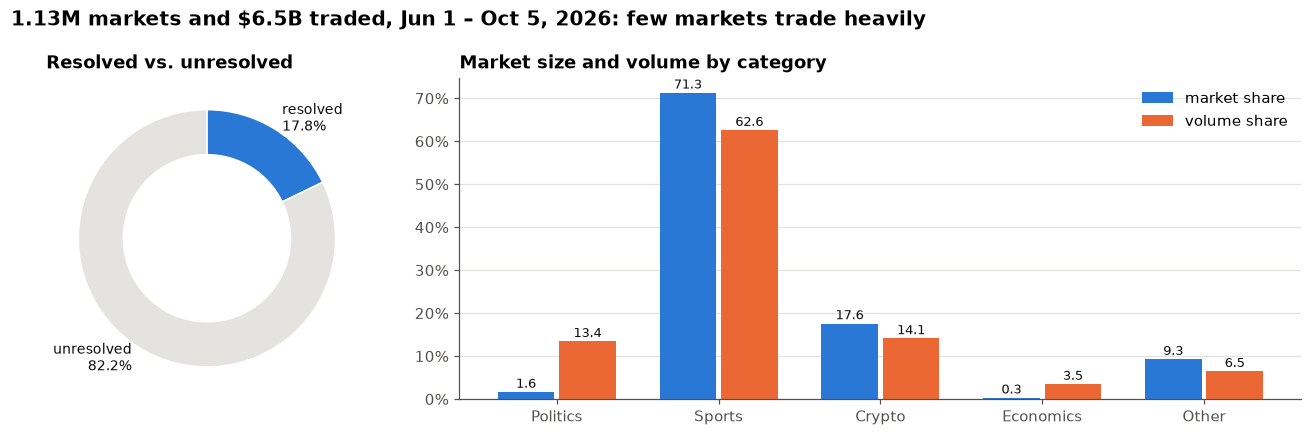

In [8]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.2]})

share = open_.resolved.mean()
ax0.pie([share, 1 - share], colors=[SERIES[0], GRID], startangle=90, counterclock=False,
        wedgeprops={"width": 0.35, "edgecolor": "white"},
        labels=[f"resolved\n{share:.1%}", f"unresolved\n{1 - share:.1%}"], textprops={"color": INK, "fontsize": 9})
ax0.set_title("Resolved vs. unresolved")

x, w = np.arange(len(GROUP_ORDER)), 0.38
for j, (col, color) in enumerate(zip(["market share", "volume share"], SERIES)):
    ax1.bar(x + (j - 0.5) * w, by_group[col] * 100, width=w - 0.03, color=color, label=col)
    for xi, v in zip(x + (j - 0.5) * w, by_group[col] * 100):
        ax1.text(xi, v + 1, f"{v:.1f}", ha="center", fontsize=8.5, color=INK)
ax1.set_xticks(x, GROUP_ORDER); ax1.grid(axis="x", visible=False)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(100)); ax1.legend(frameon=False, loc="upper right")
ax1.set_title("Market size and volume by category")

fig.suptitle(f"{len(open_) / 1e6:.2f}M markets and ${volume.dollars.sum() / 1e9:.1f}B traded, Jun 1 – Oct 5, 2026: few markets trade heavily",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reading it.** Only about 18% of the markets open in the window had resolved by Oct 5. Sports dominates both counts, about 71% of markets and 63% of volume; politics is under 2% of markets but 13% of the dollars, so it trades heavily for its size, while crypto's many short "Up or Down" markets carry a smaller share of the money than of the count. Categories come from keyword rules on the event slug and title (`build_tables.py`); the slide groups weather, tech, entertainment and other together as "Other".

## 2 · Markets created and resolved per month, and how long they last (slide 6)

A market's `start_date` is when it opened for trading. Before 2026 only markets still listed when collection started survive in the catalog, so those months are far too low; the average below uses the nine full months Feb – Oct 2026.

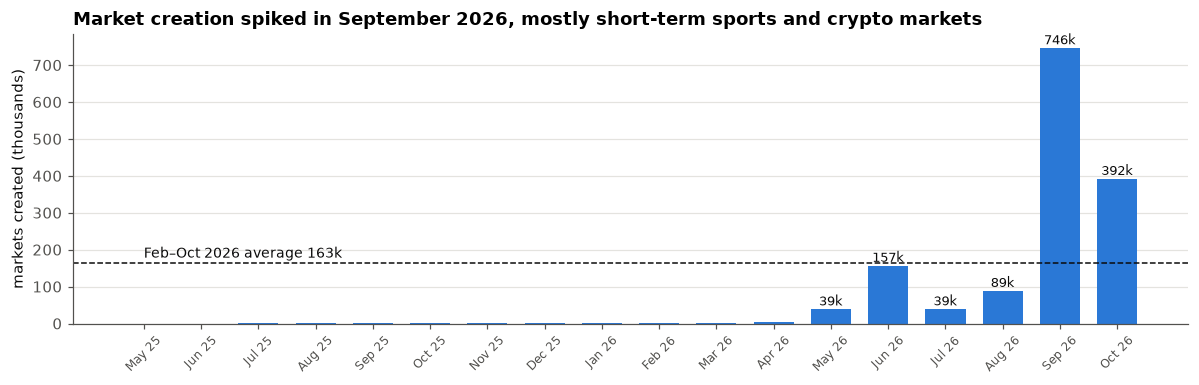

Feb–Oct 2026: mean 163,367 per month, median 39,113; Sep 2026 746,409; 2025 months average 433
September by category: {'Sports': 0.787, 'Crypto': 0.14, 'Other': 0.069, 'Politics': 0.003, 'Economics': 0.001}


In [9]:
created = markets.start_date.dt.tz_convert(None).dt.to_period("M").value_counts().sort_index()
created = created[created.index >= "2025-05"]
avg = created["2026-02":"2026-10"]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(created.index.strftime("%b %y"), created.values / 1e3, color=SERIES[0], width=0.7)
for xl, v in zip(created.index.strftime("%b %y"), created.values):
    if v >= 10_000:
        ax.text(xl, v / 1e3 + 10, f"{v / 1e3:,.0f}k", ha="center", color=INK, fontsize=8.5)
ax.axhline(avg.mean() / 1e3, color=INK, lw=1, ls="--")
ax.text(0, avg.mean() / 1e3 + 15, f"Feb–Oct 2026 average {avg.mean() / 1e3:,.0f}k", color=INK, fontsize=9)
ax.tick_params(axis="x", labelsize=8, rotation=45); ax.grid(axis="x", visible=False)
ax.set_ylabel("markets created (thousands)")
ax.set_title("Market creation spiked in September 2026, mostly short-term sports and crypto markets")
plt.tight_layout(); plt.show()
print(f"Feb–Oct 2026: mean {avg.mean():,.0f} per month, median {avg.median():,.0f}; "
      f"Sep 2026 {created['2026-09']:,}; 2025 months average {created[:'2025-12'].mean():,.0f}")
print("September by category:", (markets[markets.start_date.dt.strftime("%Y-%m") == "2026-09"].group
                                 .value_counts(normalize=True).round(3).to_dict()))

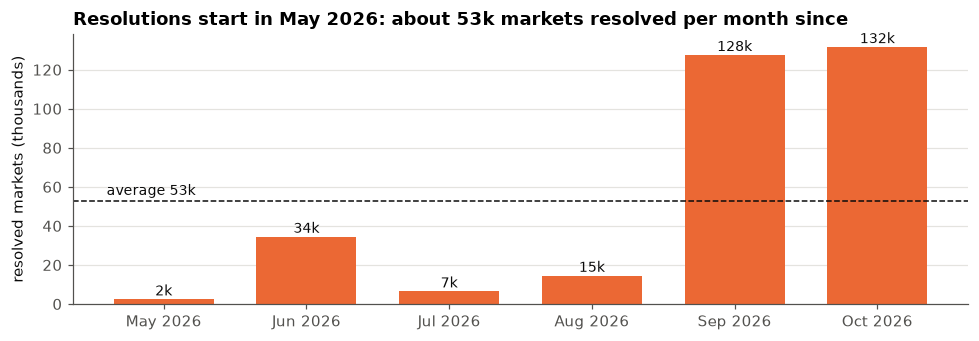

May–Oct 2026: 317,108 resolutions, mean 52,851 per month


In [10]:
by_month = res.resolved_at.dt.tz_convert(None).dt.to_period("M").value_counts().sort_index()
by_month = by_month[by_month.index >= "2026-05"]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(by_month.index.strftime("%b %Y"), by_month.values / 1e3, color=SERIES[1], width=0.7)
for x, v in zip(by_month.index.strftime("%b %Y"), by_month.values):
    ax.text(x, v / 1e3 + 2, f"{v / 1e3:,.0f}k" if v >= 1000 else f"{v}", ha="center", color=INK, fontsize=9)
ax.axhline(by_month.mean() / 1e3, color=INK, lw=1, ls="--")
ax.text(-0.4, by_month.mean() / 1e3 + 3, f"average {by_month.mean() / 1e3:,.0f}k", color=INK, fontsize=9)
ax.set_ylabel("resolved markets (thousands)"); ax.grid(axis="x", visible=False)
ax.set_title("Resolutions start in May 2026: about 53k markets resolved per month since")
plt.tight_layout(); plt.show()
print(f"May–Oct 2026: {by_month.sum():,} resolutions, mean {by_month.mean():,.0f} per month")

### Actual vs. scheduled market length

For every market that resolved May – Oct 2026: **actual** length is `start_date` to `resolved_at`, **scheduled** length is `start_date` to `end_date`. Medians, in days.

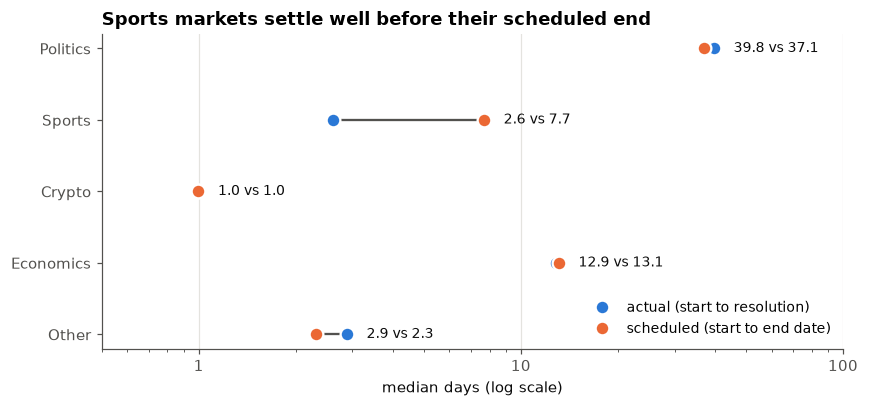

,markets,actual,scheduled
group,,,
Other,"28,679",2.9,2.3
Economics,"1,061",12.9,13.1
Crypto,"25,165",1.0,1.0
Sports,"258,685",2.6,7.7
Politics,"3,518",39.8,37.1


In [11]:
done = markets[markets.resolved_at >= pd.Timestamp("2026-05-01", tz="UTC")]
length = pd.DataFrame({
    "actual": (done.resolved_at - done.start_date).dt.total_seconds() / 86400,
    "scheduled": (done.end_date - done.start_date).dt.total_seconds() / 86400,
    "group": done.group})
med = length.groupby("group").agg(markets=("actual", "size"), actual=("actual", "median"), scheduled=("scheduled", "median"))
med = med.reindex(GROUP_ORDER[::-1])

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(med))
ax.hlines(y, med[["actual", "scheduled"]].min(axis=1), med[["actual", "scheduled"]].max(axis=1), color=MUTED, lw=1.5)
for col, color in zip(["actual", "scheduled"], SERIES):
    ax.plot(med[col], y, "o", color=color, ms=9, mec="white", mew=1.5, label=f"{col} ({'start to resolution' if col == 'actual' else 'start to end date'})")
for yi, (a, s) in enumerate(zip(med.actual, med.scheduled)):
    ax.text(max(a, s) * 1.15, yi, f"{a:.1f} vs {s:.1f}", va="center", fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_xlim(0.5, 100)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(y, med.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("median days (log scale)"); ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("Sports markets settle well before their scheduled end")
plt.tight_layout(); plt.show()
med.style.format({"markets": "{:,}", "actual": "{:.1f}", "scheduled": "{:.1f}"})

**Reading it.** Crypto markets close on schedule, in about a day. Politics and economics run close to their scheduled length. Sports shows the biggest gap: the median sports market resolves in about 2.6 days against a scheduled 7.7, because sports markets are scheduled with a buffer past the game but settle as soon as it ends.

## Takeaways

1. **The datasets only overlap from late May 2026.** Earlier catalog and trade rows are backfill of markets still listed in 2026, and resolutions barely exist before then, so every figure here stays inside late May – Oct 2026.
2. **Many markets, concentrated activity.** About 1.1M markets were open Jun 1 – Oct 5 with $6.5B traded, but only 18% had resolved; sports is 71% of markets and 63% of volume, and politics trades far above its share of markets.
3. **Creation is bursty.** About 163k markets were created per month Feb – Oct 2026, pulled up by 746k in September; a typical month is closer to 40k. About 53k resolve per month.
4. **Sports markets settle early.** Median 2.6 days actual against 7.7 scheduled; other categories close near schedule.